In [1]:
from pathlib import Path
from fed.data import load_data, clean_data, reshape_data

csv_files = list(Path("data").glob("**/API_NY.GDP.MKTP.CD*.csv"))

gdp = load_data(csv_files[0])

gdp.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3.092428e+09,3.276188e+09,3.347562e+09,2.461056e+09,2.889305e+09,3.326671e+09,3.746573e+09,4.167588e+09,NaN,NaN
1,Africa Eastern and Southern,AFE,GDP (current US$),NY.GDP.MKTP.CD,2.420573e+10,2.495893e+10,2.707328e+10,3.176919e+10,3.027960e+10,3.380623e+10,...,9.792406e+11,1.021972e+12,1.019354e+12,9.385461e+11,1.113060e+12,1.226461e+12,1.179122e+12,1.252564e+12,1.358694e+12,NaN
2,Afghanistan,AFG,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.875346e+10,1.805322e+10,1.879944e+10,1.995593e+10,1.426000e+10,1.449724e+10,1.715223e+10,1.777851e+10,NaN,NaN
3,Africa Western and Central,AFW,GDP (current US$),NY.GDP.MKTP.CD,1.190481e+10,1.270772e+10,1.363059e+10,1.446891e+10,1.580356e+10,1.692088e+10,...,6.942064e+11,7.778058e+11,1.026528e+12,9.636882e+11,1.026670e+12,1.063748e+12,9.384807e+11,7.373670e+11,8.525270e+11,NaN
4,Angola,AGO,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,8.562960e+10,9.050606e+10,8.119381e+10,5.851203e+10,7.828392e+10,1.282340e+11,1.060423e+11,1.030805e+11,1.221749e+11,NaN


In [2]:
gdp_clean = clean_data(gdp)

print(gdp_clean.shape)
gdp_clean.head()

(7, 25)


,Country Name,Country Code,2000,2001,2002,2003,2004,2005,2006,2007,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
29,Brazil,BRA,6.554482e+11,5.599836e+11,5.097953e+11,5.582337e+11,6.692894e+11,8.916338e+11,1.107627e+12,1.397114e+12,...,2.472820e+12,2.456044e+12,1.802212e+12,1.795693e+12,2.063515e+12,1.916934e+12,1.873288e+12,1.476107e+12,1.670647e+12,1.951924e+12
37,Switzerland,CHE,2.823274e+11,2.901601e+11,3.139310e+11,3.665640e+11,4.090129e+11,4.245110e+11,4.483647e+11,4.989938e+11,...,7.187484e+11,7.411681e+11,7.061990e+11,6.986078e+11,7.066604e+11,7.407665e+11,7.363848e+11,7.560962e+11,8.407100e+11,8.584790e+11
40,China,CHN,1.223755e+12,1.355037e+12,1.489822e+12,1.683903e+12,1.984197e+12,2.317551e+12,2.791498e+12,3.604056e+12,...,9.743124e+12,1.067453e+13,1.128081e+13,1.145602e+13,1.253756e+13,1.414777e+13,1.456017e+13,1.499641e+13,1.820170e+13,1.831677e+13
55,Germany,DEU,1.966981e+12,1.966381e+12,2.102351e+12,2.534716e+12,2.852318e+12,2.893393e+12,3.046309e+12,3.484057e+12,...,3.807024e+12,3.964871e+12,3.425100e+12,3.536788e+12,3.765352e+12,4.055433e+12,3.959895e+12,3.941399e+12,4.355252e+12,4.201022e+12
81,United Kingdom,GBR,1.671598e+12,1.656171e+12,1.790537e+12,2.061228e+12,2.429775e+12,2.551362e+12,2.719558e+12,3.104700e+12,...,2.796908e+12,3.085362e+12,2.945580e+12,2.706808e+12,2.699118e+12,2.897028e+12,2.875710e+12,2.724001e+12,3.194559e+12,3.181244e+12


In [3]:
gdp_long = reshape_data(gdp_clean)

print(gdp_long.shape)
gdp_long.head()

(161, 4)


,Country Name,Country Code,Year,GDP
0,Brazil,BRA,2000,6.554482e+11
1,Switzerland,CHE,2000,2.823274e+11
2,China,CHN,2000,1.223755e+12
3,Germany,DEU,2000,1.966981e+12
4,United Kingdom,GBR,2000,1.671598e+12


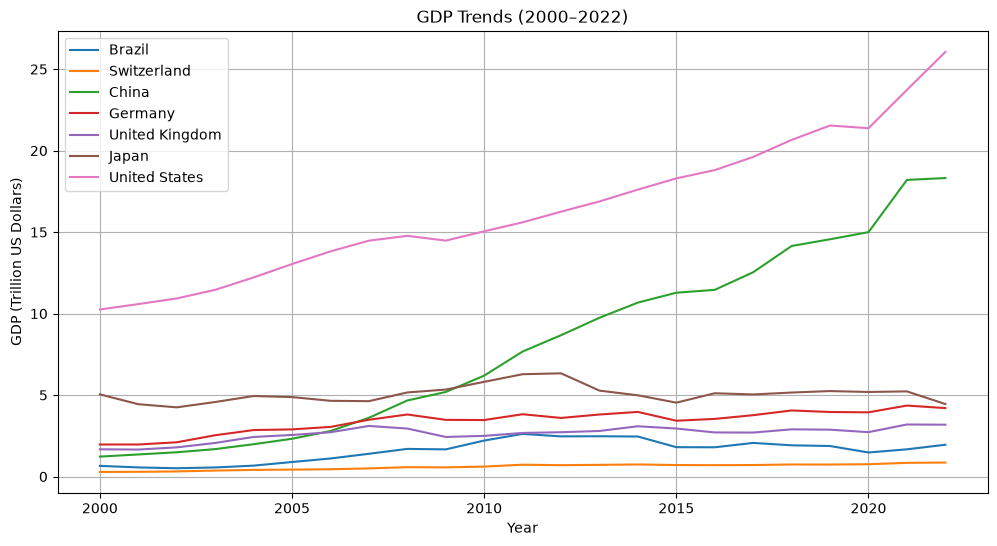

In [4]:
from fed.plot_utils import plot_gdp

plot_gdp(gdp_long)

## GDP Analysis (2000–2022)

The graph shows the GDP trends of seven countries between 2000 and 2022.

The United States had the largest GDP throughout the period, with an overall upward trend.

China experienced the fastest growth, particularly after 2010, becoming the second-largest economy among the selected countries.

Japan's GDP fluctuated over the period without a clear long-term increase in US dollar terms.

Germany and the United Kingdom showed moderate GDP growth, while Brazil and Switzerland remained relatively smaller economies.

Overall, the graph highlights significant differences in nominal GDP growth across countries. These figures are measured in current US dollars, so inflation and exchange rate movements may also affect the trends.

In [5]:
countries = ["GBR", "USA", "BRA", "JPN", "CHN", "DEU", "CHE"]

years = [str(year) for year in range(2000, 2023)]

gdp_clean = gdp.loc[
    gdp["Country Code"].isin(countries),
    ["Country Name", "Country Code"] + years
]

gdp_clean

,Country Name,Country Code,2000,2001,2002,2003,2004,2005,2006,2007,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
29,Brazil,BRA,6.554482e+11,5.599836e+11,5.097953e+11,5.582337e+11,6.692894e+11,8.916338e+11,1.107627e+12,1.397114e+12,...,2.472820e+12,2.456044e+12,1.802212e+12,1.795693e+12,2.063515e+12,1.916934e+12,1.873288e+12,1.476107e+12,1.670647e+12,1.951924e+12
37,Switzerland,CHE,2.823274e+11,2.901601e+11,3.139310e+11,3.665640e+11,4.090129e+11,4.245110e+11,4.483647e+11,4.989938e+11,...,7.187484e+11,7.411681e+11,7.061990e+11,6.986078e+11,7.066604e+11,7.407665e+11,7.363848e+11,7.560962e+11,8.407100e+11,8.584790e+11
40,China,CHN,1.223755e+12,1.355037e+12,1.489822e+12,1.683903e+12,1.984197e+12,2.317551e+12,2.791498e+12,3.604056e+12,...,9.743124e+12,1.067453e+13,1.128081e+13,1.145602e+13,1.253756e+13,1.414777e+13,1.456017e+13,1.499641e+13,1.820170e+13,1.831677e+13
55,Germany,DEU,1.966981e+12,1.966381e+12,2.102351e+12,2.534716e+12,2.852318e+12,2.893393e+12,3.046309e+12,3.484057e+12,...,3.807024e+12,3.964871e+12,3.425100e+12,3.536788e+12,3.765352e+12,4.055433e+12,3.959895e+12,3.941399e+12,4.355252e+12,4.201022e+12
81,United Kingdom,GBR,1.671598e+12,1.656171e+12,1.790537e+12,2.061228e+12,2.429775e+12,2.551362e+12,2.719558e+12,3.104700e+12,...,2.796908e+12,3.085362e+12,2.945580e+12,2.706808e+12,2.699118e+12,2.897028e+12,2.875710e+12,2.724001e+12,3.194559e+12,3.181244e+12
119,Japan,JPN,5.042382e+12,4.438793e+12,4.245947e+12,4.573413e+12,4.941485e+12,4.875648e+12,4.648059e+12,4.624670e+12,...,5.272297e+12,4.985763e+12,4.534439e+12,5.110357e+12,5.038232e+12,5.154294e+12,5.245755e+12,5.189198e+12,5.225934e+12,4.447976e+12
251,United States,USA,1.025095e+13,1.058193e+13,1.092911e+13,1.145645e+13,1.221720e+13,1.303920e+13,1.381558e+13,1.447423e+13,...,1.688068e+13,1.760814e+13,1.829502e+13,1.880491e+13,1.961210e+13,2.065652e+13,2.153998e+13,2.137528e+13,2.372564e+13,2.605461e+13


In [6]:
def clean_data(df):
    """Select GDP data for seven countries from 2000 to 2022."""

    countries = ["GBR", "USA", "BRA", "JPN", "CHN", "DEU", "CHE"]

    years = [str(year) for year in range(2000, 2023)]
    gdp_clean = df.loc[
        df["Country Code"].isin(countries),
        ["Country Name", "Country Code"] + years
    ].copy()

    return gdp_clean

In [7]:
import sys
print(sys.version)
print(sys.executable)

3.12.15 (main, Oct 13 2026, 16:47:20) [Clang 21.1.8 ]
/Users/facaibaobao/Documents/FED/.pixi/envs/default/bin/python


In [8]:
from pathlib import Path
from fed.data import load_data

csv_files = list(Path("data").glob("**/API_NY.GDP.MKTP.CD*.csv"))
print(csv_files)

[PosixPath('data/API_NY.GDP.MKTP.CD_DS2_en_csv_v2_512/API_NY.GDP.MKTP.CD_DS2_en_csv_v2_512.csv')]
